In [31]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

df = pd.read_csv(r"C:\Users\Administrator\Documents\kenya_market_prices\data\food-prices-kenya.csv")

df.head()


,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94


In [32]:
import pandas as pd

prices = pd.read_csv("data/food-prices-kenya.csv")

n_rows = prices.shape[0]
n_markets = prices['market'].nunique()
n_commodities = prices['commodity'].nunique()

In [33]:
df.columns

Index(['date', 'region', 'county', 'market', 'commodity', 'price_type', 'unit',
       'price_kes', 'price_usd'],
      dtype='str')

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2742 entries, 0 to 2741
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        2742 non-null   str    
 1   region      2683 non-null   str    
 2   county      2683 non-null   str    
 3   market      2742 non-null   str    
 4   commodity   2742 non-null   str    
 5   price_type  2742 non-null   str    
 6   unit        2742 non-null   str    
 7   price_kes   2742 non-null   float64
 8   price_usd   2742 non-null   float64
dtypes: float64(2), str(7)
memory usage: 192.9 KB


In [35]:
df.describe()

,price_kes,price_usd
count,2742.000000,2742.000000
mean,2239.335748,25.127372
std,2576.989414,28.185014
min,6.000000,0.074000
25%,55.000000,0.600000
50%,1313.335000,18.170000
75%,3733.000000,45.082500
max,10350.000000,115.150000


In [36]:
df.sample(50)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
1118,2018-02-15,Rift Valley,Baringo,Marigat,Maize,Retail,KG,53.00,0.52
1497,2008-08-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,4800.00,71.22
1840,2009-10-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,4688.00,62.30
1456,2019-02-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,8257.50,82.58
1222,2013-05-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,50.30,0.60
16,2016-06-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,80.00,0.79
1380,2012-10-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,6912.00,81.56
1640,2006-10-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,3023.75,41.93
1477,2006-11-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,3200.00,45.10
1334,2008-11-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,4117.00,52.83


In [37]:
#turn the date column into real dates
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date"].sample(20, random_state=42)


859    2015-04-15
1521   2010-08-15
1322   2007-11-15
1352   2010-05-15
2031   2006-11-15
2518   2006-03-15
2201   2007-02-15
798    2010-02-15
1110   2017-06-15
1900   2014-10-15
1364   2011-05-15
1102   2016-10-15
1601   2017-05-15
1179   2009-06-15
2030   2006-10-15
677    2014-01-15
1117   2018-01-15
1607   2017-11-15
1820   2008-02-15
2104   2013-01-15
Name: date, dtype: datetime64[us]

In [38]:
#add year and month columns
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

In [39]:
df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
1098,2016-06-15,Rift Valley,Baringo,Marigat,Maize,Retail,KG,39.0,0.39,2016,6
2280,2013-10-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,3600.0,42.38,2013,10
204,2013-03-15,Eastern,Kitui,Kitui,Beans,Retail,KG,67.0,0.78,2013,3
940,2008-02-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,29.0,0.41,2008,2
1077,2019-08-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,80.0,0.77,2019,8


In [40]:
#fill the missing county and region for the market that has none
#df["county"].isna().sum()
df["region"].isna().sum()





np.int64(59)

In [41]:
#How many rows, markets and commodities does the file have, 
df.shape
#2742 -rows, 11- columns

(2742, 11)

In [42]:
#and what are the first and last dates?

# Highest and lowest date in the dataset
highest_date = df['date'].max()
lowest_date = df['date'].min()

print(highest_date)
print(lowest_date)

#last date2019-12-15
#first date2006-01-15

2019-12-15 00:00:00
2006-01-15 00:00:00


In [43]:
#which market has no county and how many rows does that affect?
nulls = (
    df[df["county"].isna()]          # keep only rows where county is missing
    .groupby("market")
    .size()
    .sort_values(ascending=False)
)
print(nulls)

market
Hola    59
dtype: int64


In [44]:
df.duplicated().sum()

np.int64(0)

In [45]:
# Fill the missing county and region for Hola market
# Hola is located in Tana River county within the Coast region
df.loc[df['market'] == 'Hola', 'county'] = df.loc[df['market'] == 'Hola', 'county'].fillna('Tana River')
df.loc[df['market'] == 'Hola', 'region'] = df.loc[df['market'] == 'Hola', 'region'].fillna('Coast')

In [46]:
""" Compare like with like
Split the data into wholesale (per 90 KG bag) and retail (per KG) prices and never average them together. 
Add a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.
- Which units appear for wholesale maize and for retail maize?
- On average, how does the retail price per KG of maize compare with the wholesale price per KG?
"""

' Compare like with like\nSplit the data into wholesale (per 90 KG bag) and retail (per KG) prices and never average them together. \nAdd a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.\n- Which units appear for wholesale maize and for retail maize?\n- On average, how does the retail price per KG of maize compare with the wholesale price per KG?\n'

In [47]:
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])
df.sample(10)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
986,2011-12-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,60.00,0.71,2011,12,60.000000
1230,2014-01-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,53.36,0.62,2014,1,53.360000
1094,2016-01-15,Rift Valley,Baringo,Marigat,Maize,Retail,KG,41.00,0.40,2016,1,41.000000
85,2017-04-15,Coast,Kilifi,Kilifi,Beans,Retail,KG,117.30,1.14,2017,4,117.300000
303,2016-07-15,Rift Valley,Baringo,Marigat,Beans,Retail,KG,103.00,1.02,2016,7,103.000000
2116,2014-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2794.00,32.58,2014,1,31.044444
145,2008-04-15,Eastern,Kitui,Kitui,Beans,Retail,KG,40.00,0.65,2008,4,40.000000
775,2008-03-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,35.00,0.54,2008,3,35.000000
2129,2015-02-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2020.00,22.08,2015,2,22.444444
1685,2010-07-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,4227.00,51.93,2010,7,46.966667


In [48]:
#this code splits the dataset into a wholesale-only dataframe
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()
df_wholesale.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.100000
1301,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3150.0,43.93,2006,2,35.000000
1302,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3305.0,45.68,2006,3,36.722222
1303,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3060.0,43.05,2006,4,34.000000
1304,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3311.0,46.18,2006,5,36.788889


In [49]:
# this code splits the dataset into a retail-only dataframe
df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy()
df_retail.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1,87.3
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2,81.9
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3,82.2
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4,85.0
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5,90.0


In [50]:
df_wholesale.loc[df_wholesale["commodity"] == "Maize", "price_per_kg"].mean()


np.float64(28.54230389890584)

In [51]:
df_retail.loc[df_retail["commodity"] == "Maize", "price_per_kg"].mean()

np.float64(47.91992670157068)

In [52]:
#Calculate the average wholesale maize price per bag for each year and the year-on-year change. Plot the yearly average as a line chart with the price in KES on the y-axis.

df_maize = df[(df["commodity"]== "Maize") & (df["price_type"] == "Wholesale")].copy()
df_maize.head(10)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
2021,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1192.00,16.58,2006,1,13.244444
2022,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1304.00,18.19,2006,2,14.488889
2023,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1162.22,16.06,2006,3,12.913556
2024,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1277.00,17.96,2006,4,14.188889
2025,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1445.26,20.16,2006,5,16.058444
2026,2006-06-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1549.00,21.06,2006,6,17.211111
2027,2006-07-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1550.00,21.08,2006,7,17.222222
2028,2006-08-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1529.50,21.07,2006,8,16.994444
2029,2006-09-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1124.38,15.36,2006,9,12.493111
2030,2006-10-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1053.00,14.60,2006,10,11.700000


In [53]:

#Calculate the average wholesale maize price per bag for each year and the year-on-year change.
yearly_avg = (
    df_maize.groupby("year", as_index=False)["price_kes"]
    .mean()
    .rename(columns={"price_kes": "avg_price_kes"})
)[["year", "avg_price_kes"]]
yearly_avg

,year,avg_price_kes
0,2006,1395.036875
1,2007,1207.450625
2,2008,1906.319149
3,2009,2513.271875
4,2010,1773.951458
5,2011,3020.218750
6,2012,3173.782609
7,2013,2962.458333
8,2014,2993.717083
9,2015,2690.149833


In [54]:

#Which year had the highest average wholesale maize price? 2011
#Which year saw the biggest rise, and which saw the biggest fall, compared with the year before? biggest rise: 2011, biggest fall:2012

yearly_avg["yoy_change_kes"] = yearly_avg["avg_price_kes"].diff()
yearly_avg

,year,avg_price_kes,yoy_change_kes
0,2006,1395.036875,NaN
1,2007,1207.450625,-187.586250
2,2008,1906.319149,698.868524
3,2009,2513.271875,606.952726
4,2010,1773.951458,-739.320417
5,2011,3020.218750,1246.267292
6,2012,3173.782609,153.563859
7,2013,2962.458333,-211.324275
8,2014,2993.717083,31.258750
9,2015,2690.149833,-303.567250


In [55]:
yearly_avg.loc[yearly_avg["avg_price_kes"].idxmax()]

year              2017.00000
avg_price_kes     3743.68050
yoy_change_kes     981.02675
Name: 11, dtype: float64

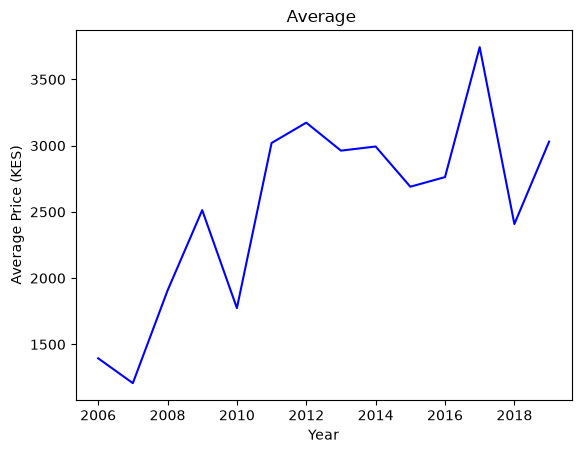

In [60]:
plt.plot(yearly_avg["year"], yearly_avg["avg_price_kes"], color="blue")
plt.xlabel("Year")
plt.ylabel("Average Price (KES)")
plt.title("Average ")
plt.show()

In [57]:
print(
    f"Highest wholesale price year: "
    f"{yearly_avg.loc[yearly_avg['avg_price_kes'].idxmax(), 'year']}"
)

Highest wholesale price year: 2017


In [58]:
print(
    f"Lowest wholesale price year: "
    f"{yearly_avg.loc[yearly_avg['avg_price_kes'].idxmin(), 'year']}"
)

Lowest wholesale price year: 2007


In [59]:
yearly_avg.loc[yearly_avg["yoy_change_kes"].idxmax()]
#yearly_avg.loc[yearly_avg["yoy_change_kes"].idxmin()]


year              2011.000000
avg_price_kes     3020.218750
yoy_change_kes    1246.267292
Name: 5, dtype: float64